# Activity: Can We Trust the AI Analyst? — FreshKart Case

**Unit 4 · AI-Assisted Visualization · LLMs for EDA & Human-in-the-Loop Visualization**  
**Student SRN:** PES2UG24CS028  
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

**FreshKart** is a quick-commerce grocery chain with **10 dark stores in 3 cities** (Bengaluru, Pune, Hyderabad). Operations head **Meera** has a leadership meeting tomorrow. She asked an AI analytics assistant:

> *"Summarise our business from January to September and tell me what went wrong in September."*

The assistant has produced the report below. **You are the analyst.** Meera will present whatever you sign off, so your job is to **verify, correct or reject** each AI insight using the data, and to say *why*.

**Ground rules (from the lecture):** every number must come from code you can inspect · an alert tells you where to look, a chart tells you what is true · the AI proposes, the human decides.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.


### The data: `freshkart_orders.csv` (synthetic)

| Column | Meaning |
|---|---|
| `order_id` | unique order reference |
| `order_date` | date of order |
| `city`, `store_id` | where the order was fulfilled |
| `zone` | `Urban` or `Suburban` delivery address |
| `delivery_partner` | `Partner A` or `Partner B` |
| `items`, `discount_pct`, `order_value` | basket size, discount applied, bill value (₹) |
| `distance_km`, `delivery_minutes`, `on_time` | delivery distance, time taken, 1 if ≤ 30 min |
| `rating` | customer rating 1–5 (blank if not given) |
| `app_sessions_7d`, `loyalty_points` | customer app activity and loyalty balance |

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_orders.csv", parse_dates=["order_date"])
df.head()

## The AI assistant's report (to be validated)

| # | Insight type | AI statement |
|---|---|---|
| 1 | Trend | "Bengaluru orders grew steadily from January to September, by about **+56 orders per month**." |
| 2 | Distribution | "The **average order value is ₹465**." |
| 3 | Comparison | "Pune orders **more than doubled** from Q2 to Q3 (**+117%**), so the Pune expansion is a huge success." |
| 4 | Comparison | "Hyderabad orders **fell 28%** in September compared with August, **because delivery service there got worse**." |
| 5 | Comparison | "**Partner B is more punctual than Partner A** (93% vs 87% on time), so we should route all orders to Partner B." |
| 6 | Correlation | "Longer delivery times go with lower ratings (**r = −0.32** among rated orders)." |
| 7 | Correlation | "Bigger discounts and bigger baskets move together (**r = 0.38**)." |
| 8 | Comparison | "Suburban orders take about **5 minutes longer** to deliver than urban orders." |
| 9 | Prediction | "**Orders will recover in October.**" |

---
## Part 1 · Is the data trustworthy? Profile before you believe

An AI narrates a profile, so a flawed profile gives a confident but flawed story. Compute the basics yourself.

In [2]:
profile = {
    "rows": len(df),
    "columns": df.shape[1],
    "duplicate_rows": int(df.duplicated().sum()),        # TODO: number of fully duplicated rows (hint: df.duplicated())
    "rating_missing_pct": round(df["rating"].isna().mean() * 100, 1),    # TODO: % of rating values that are missing, 1 decimal
    "order_id_unique_pct": round(df["order_id"].nunique() / len(df) * 100, 1),
}
profile


mean = ₹465 | median = ₹358 | skew = 13.2


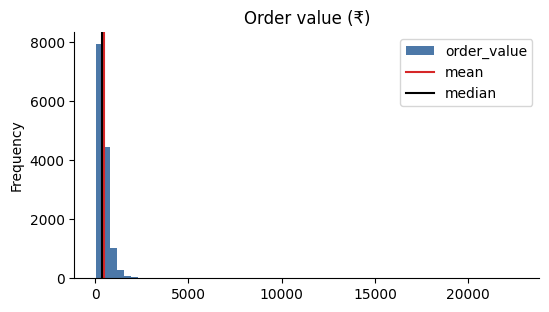

In [3]:
# From here on we work with the cleaned table (duplicates removed).
df = df.drop_duplicates().copy()

aov_mean = df["order_value"].mean()      # TODO: mean order_value
aov_median = df["order_value"].median()    # TODO: median order_value
aov_skew = round(stats.skew(df["order_value"]), 1)

if ready(aov_mean, aov_median):
    print(f"mean = ₹{aov_mean:.0f} | median = ₹{aov_median:.0f} | skew = {aov_skew}")
    df["order_value"].plot.hist(bins=60, color="#4c78a8", title="Order value (₹)")
    plt.axvline(aov_mean, color="#d62728", label="mean"); plt.axvline(aov_median, color="black", label="median")
    plt.legend(); plt.show()


In [4]:
# Where are the ratings missing?
df.groupby("city")["rating"].apply(lambda s: s.isna().mean() * 100).round(1)

**✏️ Your answer (Part 1):**
(a) Which AI insight(s) are affected by what you just found about the *average*, and how should the statement be rewritten?
(b) Insight 6 uses ratings. What risk does the missing-rating pattern create?

*Your answer:*
**(a)** **Insight 2** ("The average order value is ₹465") is directly affected. While the arithmetic mean is indeed ₹465, the distribution of order values is heavily right-skewed (skewness = 13.2) due to a long tail of high-value bulk purchases. The typical customer order has a median of only ₹358. The statement should be rewritten as:
> *"The median order value is ₹358 (mean is ₹465, pulled up by a small tail of very large orders)."*

**(b)** Over 27.6% of ratings are missing, and this missingness is non-random across cities (Hyderabad has 45.0% missing ratings compared to ~21% in Bengaluru and Pune). This creates serious **selection/response bias**: customers experiencing extreme delays or exceptional service are disproportionately more likely to rate, and Hyderabad is under-represented, making the correlation ($r = -0.32$) unrepresentative of the overall order population.


---
## Part 2 · Defaults shape the story: bin width

The assistant looked at a 1-minute-bin histogram of one store's deliveries and wrote: *"Delivery times are **multimodal**, with three separate peaks."* Look at the same 150 orders with different bin widths.

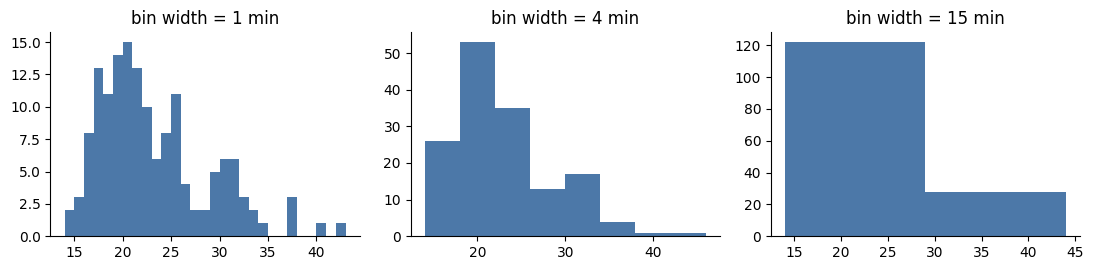

In [5]:
sample = df[df.store_id == "B3"].sample(150, random_state=1)["delivery_minutes"]
fig, axes = plt.subplots(1, 3, figsize=(11, 2.8))
for ax, w in zip(axes, [1, 4, 15]):
    ax.hist(sample, bins=np.arange(sample.min(), sample.max() + w, w), color="#4c78a8")
    ax.set_title(f"bin width = {w} min")
plt.tight_layout(); plt.show()

multimodal_supported = False    # TODO: True or False
best_bin_width = 4          # TODO: 1, 4 or 15


**✏️ Your answer (Part 2):** In one sentence, what should the analyst do before accepting a shape claim from an automated report?

*Your answer:*
The analyst should inspect the distribution across multiple bin widths (or varying density bandwidths) to confirm whether observed peaks reflect genuine underlying multi-modality rather than binning artifacts and sample noise.


---
## Part 3 · Trends, correlations and patterns

### 3a · Trend (insight 1)

slope = 56.2 orders/month | Kendall tau = 0.89, p = 0.0002


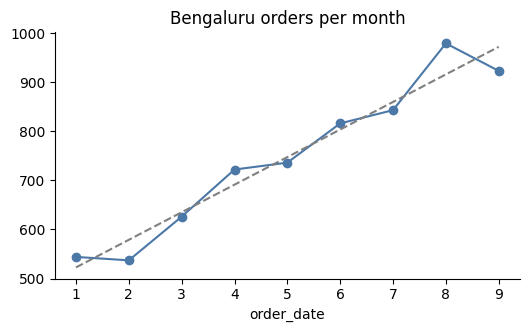

In [6]:
bengaluru = df[df.city == "Bengaluru"]
monthly = bengaluru.groupby(bengaluru["order_date"].dt.month).size()
months = monthly.index.values

slope = np.polyfit(months, monthly.values, 1)[0]   # TODO: slope of a straight-line fit of monthly orders on month (hint: np.polyfit(months, monthly.values, 1)[0])
tau, p_trend = stats.kendalltau(months, monthly.values)    # Mann–Kendall-style trend test

if ready(slope):
    print(f"slope = {slope:.1f} orders/month | Kendall tau = {tau:.2f}, p = {p_trend:.4f}")
    ax = monthly.plot(marker="o", color="#4c78a8", title="Bengaluru orders per month")
    ax.plot(months, np.polyval(np.polyfit(months, monthly.values, 1), months), "--", color="grey")
    plt.show()


### 3b · Correlation (insights 6 and 7)

discount~items r = 0.38 | minutes~rating r = -0.316 | hours~rating r = -0.316


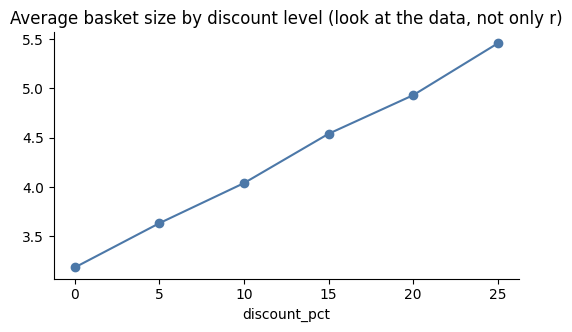

In [7]:
r_disc_items = df["discount_pct"].corr(df["items"])    # TODO: Pearson r between discount_pct and items

# Same question, different units: minutes -> hours
rated = df.dropna(subset=["rating"]).copy()
rated["delivery_hours"] = rated["delivery_minutes"] / 60
r_minutes = rated["delivery_minutes"].corr(rated["rating"])
r_hours = rated["delivery_hours"].corr(rated["rating"])
r_unchanged = bool(np.isclose(r_minutes, r_hours))     # TODO: True/False - is r the same after rescaling? (hint: np.isclose)

if ready(r_disc_items, r_unchanged):
    print(f"discount~items r = {r_disc_items:.2f} | minutes~rating r = {r_minutes:.3f} | hours~rating r = {r_hours:.3f}")
    df.groupby("discount_pct")["items"].mean().plot(marker="o", color="#4c78a8",
        title="Average basket size by discount level (look at the data, not only r)")
    plt.show()


### 3c · Scanning many pairs

The assistant also scanned **every pair** of the 7 numeric columns below and flags any pair with p < 0.05 as a "finding".

In [8]:
num_cols = ["order_value", "items", "discount_pct", "distance_km", "delivery_minutes", "app_sessions_7d", "loyalty_points"]

n_pairs = len(list(itertools.combinations(num_cols, 2)))          # TODO: number of pairs from len(num_cols) variables
expected_false = n_pairs * 0.05   # TODO: expected false 'significant' pairs at alpha = 0.05 if nothing were real
bonferroni = 0.05 / n_pairs       # TODO: Bonferroni-corrected threshold

rows = []
for a, b in itertools.combinations(num_cols, 2):
    r, p = stats.pearsonr(df[a], df[b])
    rows.append((a, b, round(r, 3), p))
scan = pd.DataFrame(rows, columns=["x", "y", "r", "p"]).sort_values("p")

if ready(n_pairs, expected_false, bonferroni):
    print(f"pairs = {n_pairs} | expected false positives = {expected_false:.2f} | Bonferroni threshold = {bonferroni:.4f}")
    flagged = scan[scan["p"] < 0.05].copy()
    flagged["survives_bonferroni"] = flagged["p"] < bonferroni
    display(flagged)


pairs = 21 | expected false positives = 1.05 | Bonferroni threshold = 0.0024
               x                 y      r             p  survives_bonferroni
0    order_value             items  0.325  0.000000e+00                 True
6          items      discount_pct  0.378  0.000000e+00                 True
15   distance_km  delivery_minutes  0.748  0.000000e+00                 True
1    order_value      discount_pct  0.066  5.802888e-15                 True
14  discount_pct    loyalty_points -0.022  8.317915e-03                False


**✏️ Your answer (3a–3c):**
(a) Insight 1 rests on 9 monthly points. Is the trend claim reasonable, and what would you show with it?
(b) Insight 7 says discounts and baskets "move together". Does the chart support the wording, and can the AI say discounts *cause* bigger baskets?
(c) Look at the flagged table. Which pair is most likely a false alarm, and what are **two** reasons you say so?

*Your answer:*
**(a)** The trend claim (+56 orders/month) is statistically supported ($Kendall\ \tau = 0.89, p = 0.0002$), but with only 9 monthly observations, seasonal fluctuations or promotional bursts could masquerade as sustainable long-term growth. The analyst should show the raw monthly scatter/line plot with a confidence interval band alongside prior-year comparisons or rolling growth rates.

**(b)** The chart shows that mean items increase monotonically with discount percentage, which supports the descriptive correlation phrasing that they "move together" ($r = 0.38$). However, the AI **cannot** claim causality: larger baskets may qualify for volume discounts (reverse causation), or price-sensitive bargain hunters may inherently buy both more discounted items and larger baskets (confounding).

**(c)** The pair `discount_pct` and `loyalty_points` is most likely a false alarm. Two reasons:
1. It **fails the Bonferroni correction**: its p-value ($p = 0.0083$) is greater than the Bonferroni threshold ($\alpha = 0.00238$).
2. The effect size is practically negligible ($r = -0.022$, explaining $< 0.05\%$ of variance) and only achieves $p < 0.05$ because of the large sample size ($N > 13,000$), possessing no business significance or causal mechanism.


### 3d · Patterns: grouping the stores

The assistant ran **PCA + k-means (k = 3)** on store-level features and proposed three store "segments".

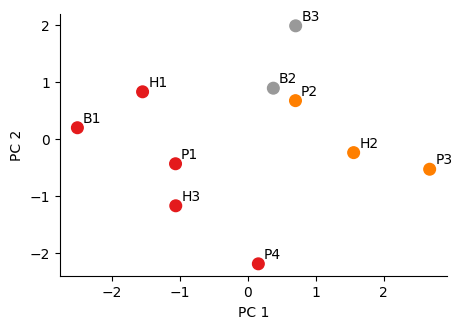

In [9]:
d = df.assign(month=df["order_date"].dt.month)
store = df.groupby("store_id").agg(
    orders=("order_id", "count"),
    median_value=("order_value", "median"),
    on_time=("on_time", "mean"),
    suburban_share=("zone", lambda s: (s == "Suburban").mean()),
    avg_discount=("discount_pct", "mean"),
    active_days=("order_date", "nunique"),
)
store["orders_per_active_day"] = store["orders"] / store["active_days"]
feats = store.drop(columns=["orders", "active_days"])

Z = StandardScaler().fit_transform(feats)
pcs = PCA(n_components=2).fit_transform(Z)
store["segment"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.scatter(pcs[:, 0], pcs[:, 1], c=store["segment"], cmap="Set1", s=70)
for sid, (x, y) in zip(store.index, pcs):
    ax.annotate(sid, (x, y), xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); plt.show()
store[["segment", "orders_per_active_day", "on_time", "suburban_share"]].round(2).sort_values("segment")

**✏️ Your answer (3d):** The AI says these are three meaningful store "types". With only 10 stores, what is one reason a human should hesitate, and what would you check before naming the segments?

*Your answer:*
With only $N = 10$ stores, k-means clustering ($k = 3$) on 4 features severely overfits to small-sample idiosyncratic noise rather than genuine operational archetypes. A human should hesitate because a single store's temporary operational anomaly can create an artificial cluster. Before naming segments, the analyst should check: (1) cluster stability (whether clusters persist across different months or when bootstrapping stores), and (2) whether differences are driven by simple external factors such as store launch maturity (e.g. newly opened stores vs established ones) or geographic zone mix.


---
## Part 4 · From an observation to hypotheses (insight 4)

**Observation:** Hyderabad orders fell sharply in September. The AI jumped straight to "service got worse". A better assistant would list *competing* hypotheses and the evidence that separates them:

| | Hypothesis | Test |
|---|---|---|
| A | Delivery service got worse | on-time % in Aug vs Sep |
| B | A data problem: some store has missing rows | rows per store per week |
| C | Discounts were cut in September | mean discount, Aug vs Sep |
| D | Customers switched to a competitor | needs competitor/customer data we do not have |

In [10]:
hyd = df[df.city == "Hyderabad"]
hyd_month = hyd.groupby(hyd["order_date"].dt.month).size()

change_pct = (hyd_month[9] - hyd_month[8]) / hyd_month[8] * 100     # TODO: % change in Hyderabad orders from August (month 8) to September (month 9)
first_test = 'B'     # TODO: which hypothesis is the cheapest to rule out first? 'A', 'B', 'C' or 'D'

if ready(change_pct, first_test):
    print(f"Hyderabad Aug -> Sep: {change_pct:.1f}% | cheapest test first: {first_test}")


Hyderabad Aug -> Sep: -28.4% | cheapest test first: B


In [11]:
# Run the tests for hypotheses B and A
weekly = hyd.groupby([pd.Grouper(key="order_date", freq="W"), "store_id"]).size().unstack(fill_value=0)
display(weekly.tail(9))

ontime = hyd.groupby(hyd["order_date"].dt.month)["on_time"].mean() * 100
ontime_change_pts = ontime[9] - ontime[8]   # TODO: on-time % in September minus on-time % in August
culprit_store = 'H2'       # TODO: which store ('H1', 'H2' or 'H3') has a gap in its weekly rows?

if ready(ontime_change_pts, culprit_store):
    print(f"on-time change Aug->Sep = {ontime_change_pts:+.1f} points | store with the gap: {culprit_store}")


store_id    H1  H2  H3
order_date            
2026-08-09  33  36  39
2026-08-16  41  32  17
2026-08-23  39  35  36
2026-08-30  46  39  28
2026-09-06  37  28  36
2026-09-13  33   0  21
2026-09-20  43   0  38
2026-09-27  38  11  31
2026-10-04  17  18  19
on-time change Aug->Sep = -0.3 points | store with the gap: H2


**✏️ Your answer (Part 4):** In two sentences, which hypotheses did the data support or rule out? Write the corrected version of insight 4 that you would be willing to show Meera.

*Your answer:*
The data completely rules out Hypothesis A (on-time delivery shifted by only -0.3 percentage points, from 89.0% to 88.7%) and strongly supports Hypothesis B, revealing that dark store H2 recorded zero orders for two consecutive weeks in September (weeks ending Sep 13 and Sep 20).
**Corrected version of Insight 4:**
> *"Hyderabad orders fell 28.4% in September primarily because dark store H2 experienced a two-week operational shutdown or data logging outage, while citywide delivery punctuality remained virtually unaffected (88.7% vs 89.0%)."*


---
## Part 5 · Validate and correct two more claims

### 5a · "Pune orders more than doubled" (insight 3)

In [12]:
pune = df[df.city == "Pune"].copy()
pune["quarter"] = pune["order_date"].dt.quarter
by_store = pune.pivot_table(index="store_id", columns="quarter", values="order_id", aggfunc="count", fill_value=0)
display(by_store)

old = by_store.loc[["P1", "P2"]]                  # the stores that were open in both Q2 and Q3
like_for_like_pct = (old[3].sum() - old[2].sum()) / old[2].sum() * 100   # TODO: % change in Q3 vs Q2 orders for these two stores (columns 2 and 3)

if ready(like_for_like_pct):
    print(f"like-for-like growth = {like_for_like_pct:+.1f}%")


quarter     1    2    3
store_id               
P1        423  423  443
P2        388  380  421
P3          0    0  483
P4          0    0  399
like-for-like growth = +7.6%


Now draw the *corrected* message. The chart below already greys the context and highlights the new stores (Knaflic: grey the context, one accent colour, title with the takeaway). **Write the title.**

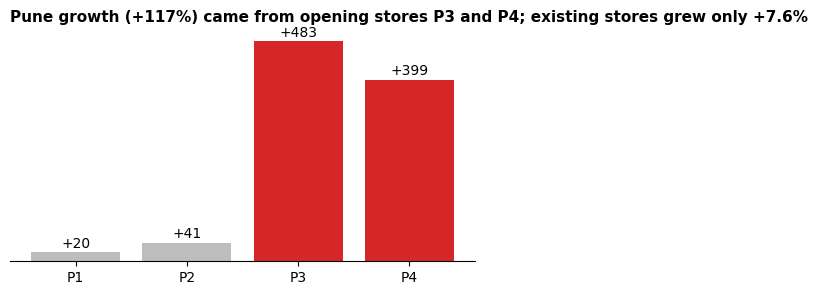

In [13]:
title = "Pune growth (+117%) came from opening stores P3 and P4; existing stores grew only +7.6%"    # TODO: a one-sentence, takeaway title (state the finding, not just "Orders by store")

change = by_store[3] - by_store[2]
colors = ["#bdbdbd" if s in ("P1", "P2") else "#d62728" for s in by_store.index]
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(change.index, change.values, color=colors)
for x, v in zip(change.index, change.values):
    ax.text(x, v + 10, f"{v:+d}", ha="center")
ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_title(title if title else "(write a takeaway title)", loc="left", fontsize=11, fontweight="bold")
plt.show()


### 5b · "Partner B is more punctual, send everything to B" (insight 5)

In [14]:
overall = df.groupby("delivery_partner")["on_time"].mean().mul(100).round(1)
mix = (pd.crosstab(df["delivery_partner"], df["zone"], normalize="index") * 100).round(0)
print("Overall on-time %:\n", overall, "\n\nShare of each partner's orders by zone (%):\n", mix)

by_zone = df.groupby(["zone", "delivery_partner"])["on_time"].mean().mul(100).round(1).unstack()   # TODO: on-time % for every (zone, partner) combination, as a table (groupby two keys, then .unstack())
better_in_every_zone = 'Partner A'   # TODO: 'Partner A' or 'Partner B' - who is better inside each zone?
phenomenon = "Simpson's paradox"             # TODO: name the effect (two words)

if ready(by_zone, better_in_every_zone, phenomenon):
    display(by_zone)
    print(f"Better inside every zone: {better_in_every_zone} | effect: {phenomenon}")


Overall on-time %:
 delivery_partner
Partner A    87.1
Partner B    93.0
Name: on_time, dtype: float64 

Share of each partner's orders by zone (%):
 zone              Suburban  Urban
delivery_partner                 
Partner A             67.0   33.0
Partner B             16.0   84.0
delivery_partner  Partner A  Partner B
zone                                  
Suburban               81.4       72.0
Urban                  98.8       96.9
Better inside every zone: Partner A | effect: Simpson's paradox


**✏️ Your answer (Part 5):** (a) Rewrite insight 3 so it is honest. (b) Explain in plain language why Partner B *looks* better overall, and what question a careful human asks before accepting a comparison like insight 5.

*Your answer:*
**(a)** **Honest rewrite of Insight 3:**
> *"Pune total orders grew 117% from Q2 to Q3 driven almost entirely by the launch of two new dark stores (P3 and P4); existing stores (P1 and P2) achieved modest like-for-like growth of 7.6%."*

**(b)** Partner B appears better overall (93.0% vs 87.1% on-time) purely due to **Simpson's paradox** driven by an unequal order allocation: 84% of Partner B's deliveries are in easier Urban zones (where on-time rates exceed 96%), whereas 67% of Partner A's deliveries are in harder Suburban zones (where on-time rates are ~72–81%). Within each individual zone, Partner A outperforms Partner B (Urban: 98.8% vs 96.9%; Suburban: 81.4% vs 72.0%). A careful human always asks: *"Is the comparison confounded by an unbalanced mix of conditions (e.g. geography, delivery difficulty, or order types) across the groups?"*


---
## Part 6 · Triage the whole report

For each AI insight decide: **Accept** (correct as stated), **Correct** (the finding is useful but the wording or number must change) or **Reject** (not supported). Then measure the AI.

In [15]:
decisions = {
    1: 'Accept',   # Bengaluru trend
    2: 'Correct',  # average order value
    3: 'Correct',  # Pune doubled
    4: 'Reject',   # Hyderabad fell because service worsened
    5: 'Reject',   # Partner B more punctual
    6: 'Accept',   # delivery time vs rating
    7: 'Accept',   # discount vs basket
    8: 'Accept',   # suburban slower (check it yourself: df.groupby("zone")["delivery_minutes"].mean())
    9: 'Reject',   # recovery prediction
}
analysts_true_insights = 7    # true insights an expert team found in this data (given)

accepted = None     # TODO: how many insights did you mark 'Accept'?
if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    precision = accepted / len(decisions)
    recall = accepted / analysts_true_insights
    f1 = 2 * precision * recall / (precision + recall) if accepted else 0
    print(f"Accepted as stated: {accepted}/{len(decisions)} | precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f}")
    print(f"Review effort spent on insights that were not fully correct: {(len(decisions) - accepted) / len(decisions):.0%}")
else:
    print("⚠ Fill in all nine decisions with 'Accept', 'Correct' or 'Reject'.")


Accepted as stated: 4/9 | precision = 0.44 | recall = 0.57 | F1 = 0.50
Review effort spent on insights that were not fully correct: 56%


**✏️ Your answer (Part 6):** Using precision and recall, would you describe this AI as an *assistant* or a *replacement* for the analyst? Justify in two sentences.

*Your answer:*
The AI is strictly an **assistant**, not a replacement: its precision as-is is only 0.44 (fewer than half the claims could be accepted without change), requiring human analysts to spend 56% of their review effort rejecting or heavily revising invalid insights. Because critical errors like Simpson's paradox and erroneous causal attributions would cause major business harm if uncorrected, human judgment and verification remain indispensable.


---
## Part 7 · Communicating, steering and validating

### 7a · Three kinds of reading
Each insight reads the data at a different level: **`data`** (restates what is plotted), **`between`** (relationships or patterns) or **`beyond`** (predictions and causal explanations; the risk zone).

In [16]:
levels = {
    2: 'data',      # "The average order value is ₹465."
    6: 'between',   # "Longer delivery times go with lower ratings."
    9: 'beyond',    # "Orders will recover in October."
}      # TODO: use 'data', 'between' or 'beyond'
print(levels)


{2: 'data', 6: 'between', 9: 'beyond'}


### 7b · Steering the assistant (interactive refinement)
Match each thing Meera types to the kind of feedback it is: **Reject**, **Constrain**, **Steer**, **Adjust** or **Pin**.

In [17]:
user_actions = {
    '"Never use pie charts in this report"': 'Constrain',
    '"Use 5-minute bins for delivery time"': 'Adjust',
    '"Focus on on-time rate by city"': 'Steer',
    '"Keep the like-for-like Pune chart on the dashboard"': 'Pin',
    '"Not this chart again"': 'Reject',
}   # TODO: replace None with one of 'Reject', 'Constrain', 'Steer', 'Adjust', 'Pin'
user_actions


### 7c · Which validation threat?
Meera now says: *"My real worry is why **repeat customers** are leaving. The AI answered a different question: how orders changed."* The AI's numbers were all computed correctly.

In [18]:
threat = 'wrong problem'   # TODO: 'wrong problem', 'wrong abstraction', 'wrong idiom' or 'wrong algorithm' (Munzner)
threat


**✏️ Your answer (Part 7):** Rewrite insight 2 *and* insight 4 as statements you would be comfortable presenting. Each rewrite should use the right measure or the right scope, avoid causal language the data cannot support, and be specific (no "interesting variation").

*Your answer:*
- **Rewritten Insight 2 (Distribution):**
  > *"The typical FreshKart order has a median value of ₹358; while the mean is ₹465, it is skewed upward by a small tail of large bulk orders (skewness 13.2)."*

- **Rewritten Insight 4 (Comparison):**
  > *"Hyderabad orders declined by 28.4% in September compared to August due to a two-week outage at store H2 where zero orders were recorded, while citywide on-time delivery rates held steady at 88.7% (compared to 89.0% in August)."*


---
## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which AI insight did you find most convincing? What made it convincing (the number, the tone, the chart, the confident wording), and would you have caught the problem without the checks?

*Your reflection:*
Insight 5 ("Partner B is more punctual than Partner A: 93% vs 87%") was the most deceptively convincing because the 6-percentage-point difference was backed by specific, plausible numbers and paired with an intuitive operational recommendation. Without disaggregating delivery performance by zone to expose Simpson's paradox, I would never have suspected that Partner A is actually superior in every individual operating zone.

**2. Choosing the level of automation.** For FreshKart, name one task where you would let the AI work with little supervision and one where you would insist on a human check. What did you use to decide (stakes, reversibility, how visible errors are)?

*Your reflection:*
I would grant high automation to automated data profiling (such as scanning for duplicate records and reporting missing-value rates), because errors are immediately verifiable and consequences are low-stakes and easily reversible. In contrast, I would insist on strict human verification for vendor allocation and root-cause performance diagnosis, where business and contract stakes are high, actions are costly to reverse, and automated claims frequently suffer from confounding and aggregation fallacies.

**3. Making trust cheaper.** Pick one problem you found (e.g. the Hyderabad gap, the missing ratings, or Partner B). What should the AI tool have *shown* (code, sample size, data gaps, uncertainty) so you could verify it faster, and what control would you want (edit, undo, switch off)?

*Your reflection:*
For the Partner B comparison (Insight 5), the tool should have automatically displayed a faceted sub-population view by delivery zone along with category order weights and sample counts. For user control, I would want interactive steering controls—specifically the ability to slice claims across key confounding variables, specify invariant constraints (e.g. "no causal claims without A/B testing"), and pin validated chart components to the executive summary.

**4. Responsibility.** If Meera presents the corrected report and one number is still wrong, who is accountable, the AI, the tool's vendor, you or Meera? What would you do differently next time to carry that responsibility well?

*Your reflection:*
As the analyst validating and signing off on the brief, I am directly responsible and accountable for the veracity of the numbers presented to executive leadership; the AI is merely an assistive drafting tool. To carry that responsibility effectively in the future, I will implement an automated regression test suite that validates all executive deck figures against reproducible SQL/Python scripts, and explicitly flag any unverified or high-uncertainty claims as provisional.
